# 04 · Ajuste de hiperparámetros de los 3 mejores candidatos

Pasan al tuning los tres mejores por RMSLE de validación cruzada en el notebook 03:
**gradient boosting** (0,674), **Chronos-Bolt** (0,676) y **bosque aleatorio** (0,680).

**Método: Optuna con el muestreador TPE**, 30 configuraciones por modelo, semilla 42.

| Alternativa | Por qué no |
|---|---|
| Búsqueda exhaustiva (`GridSearchCV`) | Con 4 a 6 hiperparámetros, una grilla de 30 puntos deja 2 o 3 valores por eje: demasiado gruesa. |
| `RandomizedSearchCV` | Reparte las 30 configuraciones al azar sin aprender de las anteriores. Cada configuración cuesta de 1 a 30 minutos (5 pliegues). |
| **Optuna (TPE)** | Las primeras 10 configuraciones son al azar; después modela qué regiones dieron menor error y concentra ahí las siguientes. Con un presupuesto fijo y caro, llega más lejos. Admite espacios condicionales (p. ej. `max_depth` solo si se limita la profundidad). |

**Reglas que no cambian respecto del notebook 03:** el mismo `X_ent`, los mismos 5 pliegues temporales
(`pliegues()`), la misma preparación y el mismo RMSLE. La prueba no se usa.

**Registro en MLflow:** una corrida padre por modelo (`tuning <modelo>`) y 30 corridas hijas anidadas, una por
configuración, con sus hiperparámetros, métricas de entrenamiento y CV, y tiempos. La padre guarda la mejor
configuración, el pipeline reentrenado con todo el entrenamiento y la mejora frente al modelo por defecto.

**¿Cuándo hay mejora?** El enunciado fija la regla: si la mejora es menor que la desviación entre pliegues, no cuenta.
Se reporta además la comparación pareada (pliegue a pliegue), que es más fina porque los pliegues difieren en
dificultad y los dos modelos se evalúan en los mismos.

In [1]:
import logging
import os
import subprocess
import sys
import time
import warnings

sys.path.insert(0, '..')
os.environ.setdefault('MLFLOW_DISABLE_AGENT_HINT', '1')
os.environ.setdefault('MLFLOW_ENABLE_ARTIFACTS_PROGRESS_BAR', 'false')
os.environ.setdefault('TQDM_DISABLE', '1')
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)

import matplotlib.pyplot as plt
import mlflow
import mlflow.sklearn
import numpy as np
import optuna
import pandas as pd
from dotenv import load_dotenv
from mlflow.models import infer_signature
from mlflow.tracking import MlflowClient
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.model_selection import cross_validate
from sklearn.pipeline import Pipeline

from src.datos import cargar_muestra
from src.pipeline import (CHRONOS_TAMANOS, HORIZONTE, METRICAS, SERIE, ChronosBolt,
                          construir_features, dividir, en_escala_log, pliegues, preparacion)

logging.getLogger('mlflow').setLevel(logging.ERROR)
optuna.logging.set_verbosity(optuna.logging.WARNING)
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 170)
pd.set_option('display.float_format', lambda v: f'{v:,.4f}')

FIGURAS = '../docs/figuras'
AZUL, NARANJA, GRIS = '#2a78d6', '#eb6834', '#b8b7b0'
TINTA, TINTA_2 = '#0b0b0b', '#52514e'
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 150, 'savefig.bbox': 'tight',
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#b8b7b0',
    'axes.labelcolor': TINTA_2, 'xtick.color': TINTA_2, 'ytick.color': TINTA_2,
    'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'font.size': 10, 'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
})


def comprobar(numero, condicion):
    if condicion:
        print(f"Comprobación {numero}: OK")
    else:
        print(f"Comprobación {numero}: revisa")


ventas, meta = cargar_muestra()
datos = construir_features(ventas)
X_ent, X_prueba, y_ent, y_prueba = dividir(datos, columnas_extra=SERIE + ['DATE'])
esquema_temporal = pliegues(X_ent)
print('Huella de la muestra:', meta['sha256'])
print(f'Entrenamiento: {len(X_ent):,} filas · {len(esquema_temporal)} pliegues de {HORIZONTE} días · '
      f'prueba sin usar: {len(X_prueba):,} filas')

C:\Users\lroja\MSDS\Data Science\Pset3\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Huella de la muestra: 4c43165b8f2b72904e5163ee431b3d9dee18bec1c820ee2a4deb035538e899cc
Entrenamiento: 593,174 filas · 5 pliegues de 16 días · prueba sin usar: 32,000 filas


In [2]:
load_dotenv('../.env')
EXPERIMENTO = os.environ.get('MLFLOW_EXPERIMENT_NAME', 'favorita-perecederos')
EXPERIMENTO_CANDIDATOS = EXPERIMENTO        # donde están las corridas por defecto (notebook 03)
mlflow.set_experiment(EXPERIMENTO)
cliente = MlflowClient()
SEMILLA = 42
N_CONFIGURACIONES = 30


def git(*argumentos):
    try:
        return subprocess.run(['git', *argumentos], capture_output=True, text=True, check=True,
                              cwd='..').stdout.strip()
    except (subprocess.CalledProcessError, FileNotFoundError):
        return None


GIT_COMMIT = git('rev-parse', 'HEAD') or 'sin-commit'
GIT_SUCIO = 'si' if git('status', '--porcelain', '--', 'src', 'notebooks') else 'no'
DATOS = {
    'tabla_origen': meta['tabla_origen'],
    'fecha_corte_snapshot': meta['fecha_corte_snapshot'],
    'huella_datos': meta['sha256'],
    'n_series': meta['n_series'],
    'filas_entrenamiento': len(X_ent),
    'esquema_cv': f'TimeSeriesSplit por fecha, {len(esquema_temporal)} pliegues de {HORIZONTE} dias',
}
ejemplo = X_ent.tail(5).assign(DATE=lambda d: d['DATE'] + pd.Timedelta(days=HORIZONTE))
CONFIABLES = ['numpy.dtype', 'src.pipeline.deshacer_log', 'src.pipeline.ReglaSemanal',
              'src.pipeline.ChronosBolt',
              'sklearn.ensemble._hist_gradient_boosting.predictor.TreePredictor',
              'sklearn.tree._tree.Tree',
              'sklearn.neural_network._stochastic_optimizers.AdamOptimizer']
print('Tracking:', mlflow.get_tracking_uri(), '| experimento:', EXPERIMENTO, '| commit:', GIT_COMMIT)

Tracking: http://127.0.0.1:5050 | experimento: favorita-perecederos | commit: 6eb6c51201cb139621b48109dc0a600998e62a9c


## 1. Espacios de búsqueda

Los rangos parten del diagnóstico del notebook 03: gradient boosting **no sobreajusta** (brecha ≈ 0, usó las 100
iteraciones), así que se le da más capacidad; el bosque **memoriza** (brecha 0,43, hojas de una fila), así que se
explora regularización; Chronos no se reentrena, así que se ajustan sus decisiones de inferencia.

Los hiperparámetros que actúan de forma multiplicativa (tasas, tamaños mínimos de hoja, penalizaciones) se buscan en
**escala logarítmica**: pasar de 0,01 a 0,02 importa tanto como pasar de 0,1 a 0,2.

| Modelo | Hiperparámetro | Rango | Escala | Por qué |
|---|---|---|---|---|
| Gradient boosting | `learning_rate` | 0,01–0,3 | log | Paso de cada árbol; el defecto es 0,1 |
| | `max_iter` | 100–800 | log | Más árboles para un modelo que no sobreajusta; la parada temprana (activa por defecto con > 10.000 filas) corta antes si deja de mejorar |
| | `max_leaf_nodes` | 15–255 | log | Complejidad de cada árbol (defecto 31) |
| | `min_samples_leaf` | 20–500 | log | Regularización: hojas con más filas (defecto 20) |
| | `l2_regularization` | 1e-6–10 | log | Penalización de los valores de las hojas (defecto 0) |
| Bosque aleatorio | `n_estimators` | 50–150 | lineal | Más árboles reducen varianza con retorno decreciente; se acota por tiempo |
| | `min_samples_leaf` | 10–200 | log | La palanca principal contra la memorización (defecto 1) |
| | `max_features` | 0,1–0,5 | lineal | Fracción de variables por división: decorrelaciona árboles (defecto 1,0 = todas) |
| | `max_samples` | 0,1–0,4 | lineal | Fracción de filas por árbol: más diversidad y árboles más rápidos |
| | `max_depth` | sin límite o 8–40 | log | Condicional: solo si se decide limitar la profundidad |
| Chronos-Bolt | tamaño | tiny, mini, small, base | categórica | 9 M a 205 M parámetros: ¿un modelo más grande pronostica mejor estas series? |
| | `contexto` | 28–366 días | log | Cuánta historia ve: más contexto da estacionalidad, menos da foco en el nivel reciente |
| | `cuantil` | 0,35–0,65 | lineal | La mediana no es necesariamente el mejor punto para el RMSLE con series intermitentes |
| | `escala` | unidades o log1p | categórica | Entregarle la serie en log1p alinea su pronóstico con la escala del RMSLE |

Los límites superiores del bosque (`n_estimators`, `max_features`, `max_samples`) están acotados por tiempo: con
los valores más altos, un ajuste tarda unos 5 minutos (30 configuraciones × 6 ajustes caben en unas 3 h).

In [3]:
def espacio_gradient_boosting(trial):
    return HistGradientBoostingRegressor(
        learning_rate=trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        max_iter=trial.suggest_int('max_iter', 100, 800, log=True),
        max_leaf_nodes=trial.suggest_int('max_leaf_nodes', 15, 255, log=True),
        min_samples_leaf=trial.suggest_int('min_samples_leaf', 20, 500, log=True),
        l2_regularization=trial.suggest_float('l2_regularization', 1e-6, 10.0, log=True),
        random_state=SEMILLA)


def espacio_bosque(trial):
    limitar = trial.suggest_categorical('limitar_profundidad', [False, True])
    return RandomForestRegressor(
        n_estimators=trial.suggest_int('n_estimators', 50, 150),
        min_samples_leaf=trial.suggest_int('min_samples_leaf', 10, 200, log=True),
        max_features=trial.suggest_float('max_features', 0.1, 0.5),
        max_samples=trial.suggest_float('max_samples', 0.1, 0.4),
        max_depth=trial.suggest_int('max_depth', 8, 40, log=True) if limitar else None,
        random_state=SEMILLA, n_jobs=-1)


def espacio_chronos(trial):
    modelo, revision = CHRONOS_TAMANOS[trial.suggest_categorical('tamano', list(CHRONOS_TAMANOS))]
    return ChronosBolt(
        contexto=trial.suggest_int('contexto', 28, 366, log=True),
        cuantil=trial.suggest_float('cuantil', 0.35, 0.65),
        escala=trial.suggest_categorical('escala', ['unidades', 'log1p']),
        modelo=modelo, revision=revision)


# preparar: antepone preparacion(); escala_log: entrena sobre log1p(y);
# entrenamiento: calcula el error de entrenamiento (Chronos no aprende de X).
TUNING = {
    'gradient boosting': dict(espacio=espacio_gradient_boosting, familia='boosting',
                              preparar=True, escala_log=True, entrenamiento=True,
                              # l2_regularization=0 por defecto; 1e-6 es el mínimo del espacio (log)
                              por_defecto={'learning_rate': 0.1, 'max_iter': 100, 'max_leaf_nodes': 31,
                                           'min_samples_leaf': 20, 'l2_regularization': 1e-6}),
    'bosque aleatorio': dict(espacio=espacio_bosque, familia='bagging',
                             preparar=True, escala_log=True, entrenamiento=True),
    'chronos bolt': dict(espacio=espacio_chronos, familia='state of the art',
                         preparar=False, escala_log=False, entrenamiento=False,
                         # contexto=366 cubre toda la historia disponible (equivale a None)
                         por_defecto={'tamano': 'small', 'contexto': 366, 'cuantil': 0.5, 'escala': 'unidades'}),
}

## 2. Función de ajuste

**La configuración por defecto entra como la n.º 1** en gradient boosting y en Chronos, cuyos valores por defecto caen
dentro del espacio. Así la búsqueda no puede terminar peor que el modelo por defecto, y la configuración 1 debe
reproducir el RMSLE del notebook 03 (comprobación de reproducibilidad). En el bosque no se puede: su valor por
defecto (`min_samples_leaf=1`) queda fuera del espacio a propósito, porque es la causa de la memorización.

`afinar(nombre)` abre la corrida padre, deja que Optuna proponga 30 configuraciones y evalúa cada una con
`cross_validate` sobre los 5 pliegues en una corrida hija. Al final reentrena la mejor con todo el entrenamiento,
la guarda como artefacto de la padre y la compara con la corrida por defecto del notebook 03 (que se lee de MLflow,
con su RMSLE de cada pliegue).

In [4]:
resultados = {}
estudios = {}


def armar(modelo, preparar, escala_log):
    pasos = [('preparar', preparacion())] if preparar else []
    pasos.append(('modelo', en_escala_log(modelo) if escala_log else modelo))
    return Pipeline(pasos)


def corrida_por_defecto(nombre):
    """La corrida del notebook 03 (fase candidato) y su RMSLE por pliegue."""
    fila = mlflow.search_runs(
        experiment_names=[EXPERIMENTO_CANDIDATOS],
        filter_string=f"tags.fase = 'candidato' and tags.mlflow.runName = '{nombre}'",
        order_by=['attributes.start_time DESC'], max_results=1).iloc[0]
    historia = cliente.get_metric_history(fila['run_id'], 'rmsle_cv_pliegue')
    return fila, np.array([m.value for m in sorted(historia, key=lambda m: m.step)])


def validar(pipeline, entrenamiento):
    inicio = time.perf_counter()
    puntajes = cross_validate(pipeline, X_ent, y_ent, cv=esquema_temporal, scoring=METRICAS,
                              return_train_score=entrenamiento)
    errores = -puntajes['test_rmsle']
    metricas = {'rmsle_cv': errores.mean(), 'rmsle_cv_std': errores.std(),
                'mae_cv': -puntajes['test_mae'].mean(), 'sesgo_cv': puntajes['test_sesgo'].mean(),
                'segundos_cv': time.perf_counter() - inicio,
                'segundos_ajuste_pliegue_5': puntajes['fit_time'][-1]}
    if entrenamiento:
        metricas['rmsle_entrenamiento'] = -puntajes['train_rmsle'].mean()
        metricas['brecha'] = metricas['rmsle_cv'] - metricas['rmsle_entrenamiento']
    return errores, metricas


def afinar(nombre, n=N_CONFIGURACIONES):
    cfg = TUNING[nombre]
    defecto, pliegues_defecto = corrida_por_defecto(nombre)
    etiquetas = {'fase': 'tuning', 'familia': cfg['familia'], 'git_commit': GIT_COMMIT,
                 'git_cambios_sin_commit': GIT_SUCIO}
    inicio_total = time.perf_counter()

    with mlflow.start_run(run_name=f'tuning {nombre}') as padre:
        mlflow.set_tags({**etiquetas, 'rol': 'padre', 'metodo': 'optuna TPE'})
        mlflow.log_params({**DATOS, 'semilla': SEMILLA, 'n_configuraciones': n,
                           'sampler': f'TPESampler(seed={SEMILLA})', 'run_id_por_defecto': defecto['run_id']})

        def objetivo(trial):
            modelo = cfg['espacio'](trial)
            pipeline = armar(modelo, cfg['preparar'], cfg['escala_log'])
            with mlflow.start_run(run_name=f'{nombre} #{trial.number + 1:02d}', nested=True):
                mlflow.set_tags({**etiquetas, 'rol': 'configuracion', 'configuracion': trial.number + 1,
                                 'es_por_defecto': 'si' if trial.number == 0 and 'por_defecto' in cfg else 'no'})
                mlflow.log_params({**modelo.get_params(), **trial.params, **DATOS, 'semilla': SEMILLA})
                errores, metricas = validar(pipeline, cfg['entrenamiento'])
                for paso, error in enumerate(errores, start=1):
                    mlflow.log_metric('rmsle_cv_pliegue', error, step=paso)
                mlflow.log_metrics(metricas)
            trial.set_user_attr('pliegues', errores.tolist())
            for clave in ['rmsle_cv_std', 'rmsle_entrenamiento', 'brecha', 'segundos_cv']:
                if clave in metricas:
                    trial.set_user_attr(clave, float(metricas[clave]))
            print(f"  #{trial.number + 1:02d}  CV {metricas['rmsle_cv']:.4f} ± {metricas['rmsle_cv_std']:.4f}"
                  f"  {metricas['segundos_cv']:6.0f} s  {trial.params}", flush=True)
            return metricas['rmsle_cv']

        estudio = optuna.create_study(direction='minimize', study_name=nombre,
                                      sampler=optuna.samplers.TPESampler(seed=SEMILLA))
        if 'por_defecto' in cfg:      # la configuración 1 es la del notebook 03
            estudio.enqueue_trial(cfg['por_defecto'])
        estudio.optimize(objetivo, n_trials=n)
        mejor = estudio.best_trial
        pliegues_mejor = np.array(mejor.user_attrs['pliegues'])

        # La mejor configuración, reentrenada con todo el entrenamiento: es el artefacto de la padre.
        modelo = cfg['espacio'](optuna.trial.FixedTrial(mejor.params))
        pipeline = armar(modelo, cfg['preparar'], cfg['escala_log'])
        inicio = time.perf_counter()
        pipeline.fit(X_ent, y_ent)
        segundos = time.perf_counter() - inicio
        mlflow.sklearn.log_model(pipeline, name='modelo', input_example=ejemplo,
                                 signature=infer_signature(ejemplo, pipeline.predict(ejemplo)),
                                 code_paths=['../src'], skops_trusted_types=CONFIABLES)

        mejora = pliegues_defecto.mean() - pliegues_mejor.mean()
        pareada = 100 * (1 - pliegues_mejor / pliegues_defecto)
        resumen = {
            'rmsle_cv': pliegues_mejor.mean(), 'rmsle_cv_std': pliegues_mejor.std(),
            'rmsle_cv_por_defecto': pliegues_defecto.mean(), 'rmsle_cv_std_por_defecto': pliegues_defecto.std(),
            'mejora': mejora, 'mejora_pct': 100 * mejora / pliegues_defecto.mean(),
            'mejora_pareada_pct': pareada.mean(), 'mejora_pareada_std_pct': pareada.std(),
            'pliegues_mejores': int((pliegues_mejor < pliegues_defecto).sum()),
            'segundos': segundos, 'segundos_tuning': time.perf_counter() - inicio_total,
        }
        for clave in ['rmsle_entrenamiento', 'brecha']:
            if clave in mejor.user_attrs:
                resumen[clave] = mejor.user_attrs[clave]
        for paso, error in enumerate(pliegues_mejor, start=1):
            mlflow.log_metric('rmsle_cv_pliegue', error, step=paso)
        mlflow.log_metrics(resumen)
        mlflow.log_params({f'mejor_{k}': v for k, v in mejor.params.items()})
        supera = mejora > pliegues_mejor.std()
        mlflow.set_tags({'mejor_configuracion': mejor.number + 1, 'modelo_guardado': 'si',
                         'mejora_supera_desviacion': 'si' if supera else 'no'})
        mlflow.log_text(estudio.trials_dataframe().to_csv(index=False), 'tuning/configuraciones.csv')

    estudios[nombre] = estudio
    resultados[nombre] = {'modelo': nombre, **resumen, 'supera_desviacion': supera,
                          'mejor_configuracion': mejor.number + 1, 'mejores_parametros': mejor.params,
                          'run_id': padre.info.run_id, 'pliegues': pliegues_mejor,
                          'pliegues_por_defecto': pliegues_defecto}
    print(f"\n{nombre}: por defecto {pliegues_defecto.mean():.4f} → ajustado {pliegues_mejor.mean():.4f} "
          f"± {pliegues_mejor.std():.4f} (configuración #{mejor.number + 1}); mejora {mejora:.4f} "
          f"({resumen['mejora_pct']:.2f} %), pareada {pareada.mean():.2f} ± {pareada.std():.2f} %; "
          f"¿supera la desviación entre pliegues? {'sí' if supera else 'no'}")

## 3. Chronos-Bolt

In [5]:
afinar('chronos bolt')

🏃 View run chronos bolt #01 at: http://127.0.0.1:5050/#/experiments/3/runs/9b43d00cbd054a0da1f4f8a59c8e1315
🧪 View experiment at: http://127.0.0.1:5050/#/experiments/3
  #01  CV 0.6757 ± 0.0280      72 s  {'tamano': 'small', 'contexto': 366, 'cuantil': 0.5, 'escala': 'unidades'}


🏃 View run chronos bolt #02 at: http://127.0.0.1:5050/#/experiments/3/runs/27d7426c56f54e048d78544884536710
🧪 View experiment at: http://127.0.0.1:5050/#/experiments/3
  #02  CV 0.7134 ± 0.0277       9 s  {'tamano': 'mini', 'contexto': 41, 'cuantil': 0.3967983561008608, 'escala': 'log1p'}


🏃 View run chronos bolt #03 at: http://127.0.0.1:5050/#/experiments/3/runs/ea65baba9bf04d149e36064904ef7bc0
🧪 View experiment at: http://127.0.0.1:5050/#/experiments/3
  #03  CV 0.6961 ± 0.0281     226 s  {'tamano': 'base', 'contexto': 237, 'cuantil': 0.4137017332034828, 'escala': 'log1p'}


🏃 View run chronos bolt #04 at: http://127.0.0.1:5050/#/experiments/3/runs/8a184edbd45c443882f805ba031eae83
🧪 View experiment at: http://127.0.0.1:5050/#/experiments/3
  #04  CV 0.7043 ± 0.0262      18 s  {'tamano': 'mini', 'contexto': 134, 'cuantil': 0.39184815819561253, 'escala': 'log1p'}


🏃 View run chronos bolt #05 at: http://127.0.0.1:5050/#/experiments/3/runs/1054f1ed1c5a4778a02f34e9079d8a1e
🧪 View experiment at: http://127.0.0.1:5050/#/experiments/3
  #05  CV 0.7039 ± 0.0263      15 s  {'tamano': 'mini', 'contexto': 128, 'cuantil': 0.3639351238159993, 'escala': 'unidades'}


🏃 View run chronos bolt #06 at: http://127.0.0.1:5050/#/experiments/3/runs/d061a862fbf943758bb6eab7bd9603cf
🧪 View experiment at: http://127.0.0.1:5050/#/experiments/3
  #06  CV 0.7044 ± 0.0273      20 s  {'tamano': 'small', 'contexto': 61, 'cuantil': 0.37930163420191515, 'escala': 'unidades'}


... (21 outputs left out)

🏃 View run chronos bolt #28 at: http://127.0.0.1:5050/#/experiments/3/runs/39c0b1af8bef4bb4b0b000385df99c1b
🧪 View experiment at: http://127.0.0.1:5050/#/experiments/3
  #28  CV 0.6822 ± 0.0253      10 s  {'tamano': 'tiny', 'contexto': 174, 'cuantil': 0.48569789386328255, 'escala': 'unidades'}


🏃 View run chronos bolt #29 at: http://127.0.0.1:5050/#/experiments/3/runs/b830506803874528b1a811df594bee6e
🧪 View experiment at: http://127.0.0.1:5050/#/experiments/3
  #29  CV 0.6812 ± 0.0279      44 s  {'tamano': 'small', 'contexto': 198, 'cuantil': 0.4699577528248411, 'escala': 'log1p'}


🏃 View run chronos bolt #30 at: http://127.0.0.1:5050/#/experiments/3/runs/58d2ef9e00c6465caf753d405c9060f7
🧪 View experiment at: http://127.0.0.1:5050/#/experiments/3
  #30  CV 0.6824 ± 0.0274      14 s  {'tamano': 'tiny', 'contexto': 332, 'cuantil': 0.5290622755835677, 'escala': 'unidades'}


🏃 View run tuning chronos bolt at: http://127.0.0.1:5050/#/experiments/3/runs/86c8cfe4156645438feadecd96d08777
🧪 View experiment at: http://127.0.0.1:5050/#/experiments/3

chronos bolt: por defecto 0.6757 → ajustado 0.6737 ± 0.0279 (configuración #26); mejora 0.0021 (0.31 %), pareada 0.31 ± 0.31 %; ¿supera la desviación entre pliegues? no


## 4. Gradient boosting

In [6]:
afinar('gradient boosting')

🏃 View run gradient boosting #01 at: http://127.0.0.1:5050/#/experiments/3/runs/0495f49daeda4842b16e91b029337002
🧪 View experiment at: http://127.0.0.1:5050/#/experiments/3
  #01  CV 0.6744 ± 0.0263     109 s  {'learning_rate': 0.1, 'max_iter': 100, 'max_leaf_nodes': 31, 'min_samples_leaf': 20, 'l2_regularization': 1e-06}


🏃 View run gradient boosting #02 at: http://127.0.0.1:5050/#/experiments/3/runs/19ecdda08ce64d4394aaf0b79352d4e9
🧪 View experiment at: http://127.0.0.1:5050/#/experiments/3
  #02  CV 0.6712 ± 0.0280     732 s  {'learning_rate': 0.03574712922600244, 'max_iter': 722, 'max_leaf_nodes': 118, 'min_samples_leaf': 136, 'l2_regularization': 1.2363188277052228e-05}


🏃 View run gradient boosting #03 at: http://127.0.0.1:5050/#/experiments/3/runs/6e5b1ae09b71477795c052bfc0386812
🧪 View experiment at: http://127.0.0.1:5050/#/experiments/3
  #03  CV 0.6942 ± 0.0246     267 s  {'learning_rate': 0.01699897838270077, 'max_iter': 112, 'max_leaf_nodes': 174, 'min_samples_leaf': 137, 'l2_regularization': 0.090470719575684}


🏃 View run gradient boosting #04 at: http://127.0.0.1:5050/#/experiments/3/runs/d9c5b0c171044495b7d3be83d3a357c3
🧪 View experiment at: http://127.0.0.1:5050/#/experiments/3
  #04  CV 0.6709 ± 0.0278    1094 s  {'learning_rate': 0.010725209743171996, 'max_iter': 752, 'max_leaf_nodes': 158, 'min_samples_leaf': 39, 'l2_regularization': 1.8740223688836324e-05}


🏃 View run gradient boosting #05 at: http://127.0.0.1:5050/#/experiments/3/runs/b00cec9a24ea466eaebf0453c73c6f62
🧪 View experiment at: http://127.0.0.1:5050/#/experiments/3
  #05  CV 0.6782 ± 0.0260     273 s  {'learning_rate': 0.018659959624904916, 'max_iter': 188, 'max_leaf_nodes': 65, 'min_samples_leaf': 79, 'l2_regularization': 0.00010929592787219404}


🏃 View run gradient boosting #06 at: http://127.0.0.1:5050/#/experiments/3/runs/7d29b219437145c9af34cfdd312fe6ec
🧪 View experiment at: http://127.0.0.1:5050/#/experiments/3
  #06  CV 0.6740 ± 0.0260     134 s  {'learning_rate': 0.08012737503998542, 'max_iter': 133, 'max_leaf_nodes': 34, 'min_samples_leaf': 64, 'l2_regularization': 0.0015577217702693043}


... (21 outputs left out)

🏃 View run gradient boosting #28 at: http://127.0.0.1:5050/#/experiments/3/runs/53d4a6e720e943dcb2c625fa7c263b62
🧪 View experiment at: http://127.0.0.1:5050/#/experiments/3
  #28  CV 0.6707 ± 0.0282     887 s  {'learning_rate': 0.02444710464211772, 'max_iter': 678, 'max_leaf_nodes': 219, 'min_samples_leaf': 50, 'l2_regularization': 0.00013229897104437795}


🏃 View run gradient boosting #29 at: http://127.0.0.1:5050/#/experiments/3/runs/d39a4d74655b4a6bba3b1dfd5188f2a1
🧪 View experiment at: http://127.0.0.1:5050/#/experiments/3
  #29  CV 0.6707 ± 0.0280    1093 s  {'learning_rate': 0.01655528390116161, 'max_iter': 746, 'max_leaf_nodes': 216, 'min_samples_leaf': 69, 'l2_regularization': 2.8289136007774157e-06}


🏃 View run gradient boosting #30 at: http://127.0.0.1:5050/#/experiments/3/runs/46dd2244b4dc4ace8b060dc9c1e23a3d
🧪 View experiment at: http://127.0.0.1:5050/#/experiments/3
  #30  CV 0.6713 ± 0.0284     579 s  {'learning_rate': 0.04544126975500246, 'max_iter': 421, 'max_leaf_nodes': 241, 'min_samples_leaf': 58, 'l2_regularization': 0.00012969181469729544}


🏃 View run tuning gradient boosting at: http://127.0.0.1:5050/#/experiments/3/runs/c566d0424ee24c5f9088a448818764b5
🧪 View experiment at: http://127.0.0.1:5050/#/experiments/3

gradient boosting: por defecto 0.6744 → ajustado 0.6697 ± 0.0284 (configuración #16); mejora 0.0047 (0.70 %), pareada 0.71 ± 0.40 %; ¿supera la desviación entre pliegues? no


## 5. Bosque aleatorio

In [7]:
afinar('bosque aleatorio')

🏃 View run bosque aleatorio #01 at: http://127.0.0.1:5050/#/experiments/3/runs/7fe579676ce74534b46b2e8f984d3167
🧪 View experiment at: http://127.0.0.1:5050/#/experiments/3
  #01  CV 0.6841 ± 0.0265      96 s  {'limitar_profundidad': True, 'n_estimators': 123, 'min_samples_leaf': 59, 'max_features': 0.1624074561769746, 'max_samples': 0.1467983561008608, 'max_depth': 8}


🏃 View run bosque aleatorio #02 at: http://127.0.0.1:5050/#/experiments/3/runs/ff7a501895be452a9d27c669a13fb415
🧪 View experiment at: http://127.0.0.1:5050/#/experiments/3
  #02  CV 0.6749 ± 0.0268     593 s  {'limitar_profundidad': False, 'n_estimators': 121, 'min_samples_leaf': 10, 'max_features': 0.4879639408647978, 'max_samples': 0.34973279224012654}


🏃 View run bosque aleatorio #03 at: http://127.0.0.1:5050/#/experiments/3/runs/aa309fd44a1541ed8b2acd5dd0bd5d9d
🧪 View experiment at: http://127.0.0.1:5050/#/experiments/3
  #03  CV 0.6770 ± 0.0263     155 s  {'limitar_profundidad': False, 'n_estimators': 68, 'min_samples_leaf': 24, 'max_features': 0.3099025726528951, 'max_samples': 0.22958350559263474}


🏃 View run bosque aleatorio #04 at: http://127.0.0.1:5050/#/experiments/3/runs/7c0866a4f9cb4ec8a46a447b88fe2410
🧪 View experiment at: http://127.0.0.1:5050/#/experiments/3
  #04  CV 0.6771 ± 0.0263     127 s  {'limitar_profundidad': True, 'n_estimators': 64, 'min_samples_leaf': 23, 'max_features': 0.2465447373174767, 'max_samples': 0.2368209952651108, 'max_depth': 28}


🏃 View run bosque aleatorio #05 at: http://127.0.0.1:5050/#/experiments/3/runs/196872d038e944b58ff0e100f3070e58
🧪 View experiment at: http://127.0.0.1:5050/#/experiments/3
  #05  CV 0.6815 ± 0.0264     143 s  {'limitar_profundidad': True, 'n_estimators': 109, 'min_samples_leaf': 11, 'max_features': 0.34301794076057535, 'max_samples': 0.15115723710618748, 'max_depth': 8}


🏃 View run bosque aleatorio #06 at: http://127.0.0.1:5050/#/experiments/3/runs/2cc25c9d2a3a49cd96a22bfa42ca802a
🧪 View experiment at: http://127.0.0.1:5050/#/experiments/3
  #06  CV 0.6777 ± 0.0263     189 s  {'limitar_profundidad': True, 'n_estimators': 131, 'min_samples_leaf': 24, 'max_features': 0.13906884560255356, 'max_samples': 0.3052699079536471, 'max_depth': 16}


... (21 outputs left out)

🏃 View run bosque aleatorio #28 at: http://127.0.0.1:5050/#/experiments/3/runs/76cfb1b8b8c8422cacb13ae77be2e84a
🧪 View experiment at: http://127.0.0.1:5050/#/experiments/3
  #28  CV 0.6748 ± 0.0262     428 s  {'limitar_profundidad': False, 'n_estimators': 149, 'min_samples_leaf': 12, 'max_features': 0.30468777624028404, 'max_samples': 0.3050303503923887}


🏃 View run bosque aleatorio #29 at: http://127.0.0.1:5050/#/experiments/3/runs/1b8c40c71e44462297bdd38eef6e7d4d
🧪 View experiment at: http://127.0.0.1:5050/#/experiments/3
  #29  CV 0.6742 ± 0.0263     442 s  {'limitar_profundidad': False, 'n_estimators': 144, 'min_samples_leaf': 10, 'max_features': 0.28007243325089376, 'max_samples': 0.3626728633395267}


🏃 View run bosque aleatorio #30 at: http://127.0.0.1:5050/#/experiments/3/runs/79aa0a2bb685484fbacf4305d7a545d0
🧪 View experiment at: http://127.0.0.1:5050/#/experiments/3
  #30  CV 0.6754 ± 0.0261     206 s  {'limitar_profundidad': False, 'n_estimators': 130, 'min_samples_leaf': 10, 'max_features': 0.14319090425049208, 'max_samples': 0.2762749916869303}


🏃 View run tuning bosque aleatorio at: http://127.0.0.1:5050/#/experiments/3/runs/a1df2c799e0f45aabc0d001167f74e2c
🧪 View experiment at: http://127.0.0.1:5050/#/experiments/3

bosque aleatorio: por defecto 0.6795 → ajustado 0.6742 ± 0.0263 (configuración #17); mejora 0.0053 (0.79 %), pareada 0.78 ± 0.40 %; ¿supera la desviación entre pliegues? no


## 6. Resultados

In [8]:
tabla_tuning = (pd.DataFrame(resultados.values())
                .set_index('modelo').sort_values('rmsle_cv'))
columnas = ['rmsle_cv_por_defecto', 'rmsle_cv_std_por_defecto', 'rmsle_cv', 'rmsle_cv_std',
            'rmsle_entrenamiento', 'brecha', 'mejora', 'mejora_pct', 'mejora_pareada_pct',
            'mejora_pareada_std_pct', 'pliegues_mejores', 'supera_desviacion', 'mejor_configuracion',
            'segundos', 'segundos_tuning']
tabla_tuning[columnas]

,rmsle_cv_por_defecto,rmsle_cv_std_por_defecto,rmsle_cv,rmsle_cv_std,rmsle_entrenamiento,brecha,mejora,mejora_pct,mejora_pareada_pct,mejora_pareada_std_pct,pliegues_mejores,supera_desviacion,mejor_configuracion,segundos,segundos_tuning
modelo,,,,,,,,,,,,,,,
gradient boosting,0.6744,0.0263,0.6697,0.0284,0.6209,0.0488,0.0047,0.7003,0.7126,0.4002,4,False,16,121.0142,"17,313.4479"
chronos bolt,0.6757,0.0280,0.6737,0.0279,NaN,NaN,0.0021,0.3102,0.3097,0.3090,3,False,26,0.1229,"1,667.0481"
bosque aleatorio,0.6795,0.0270,0.6742,0.0263,0.6217,0.0525,0.0053,0.7854,0.7818,0.4021,5,False,17,114.5338,"10,400.8938"


In [9]:
for nombre, fila in tabla_tuning.iterrows():
    print(f'{nombre}: {fila["mejores_parametros"]}')

# 30 configuraciones completas por modelo, y 30 corridas hijas bajo cada padre en MLflow.
hijas = {nombre: len(mlflow.search_runs(experiment_names=[EXPERIMENTO],
                                        filter_string=f"tags.mlflow.parentRunId = '{fila['run_id']}'"))
         for nombre, fila in tabla_tuning.iterrows()}
print('Corridas hijas por modelo:', hijas)
completas = all(len([t for t in e.trials if t.state == optuna.trial.TrialState.COMPLETE]) >= N_CONFIGURACIONES
                for e in estudios.values())
comprobar(1, completas and all(n >= N_CONFIGURACIONES for n in hijas.values()))
# La configuración 1 (por defecto) reproduce el RMSLE de CV del notebook 03 (tolerancia 5e-4:
# en gradient boosting, l2_regularization=1e-6 en vez de 0).
reproduce = all(abs(estudios[n].trials[0].value - resultados[n]['rmsle_cv_por_defecto']) < 5e-4
                for n in estudios if 'por_defecto' in TUNING[n])
comprobar(2, reproduce)

gradient boosting: {'learning_rate': 0.03805275421447413, 'max_iter': 522, 'max_leaf_nodes': 181, 'min_samples_leaf': 33, 'l2_regularization': 0.0007847949252111567}
chronos bolt: {'tamano': 'small', 'contexto': 306, 'cuantil': 0.45659434482352373, 'escala': 'unidades'}
bosque aleatorio: {'limitar_profundidad': False, 'n_estimators': 138, 'min_samples_leaf': 10, 'max_features': 0.3252675434604039, 'max_samples': 0.3596575602787643}


Corridas hijas por modelo: {'gradient boosting': 30, 'chronos bolt': 30, 'bosque aleatorio': 30}
Comprobación 1: OK
Comprobación 2: OK


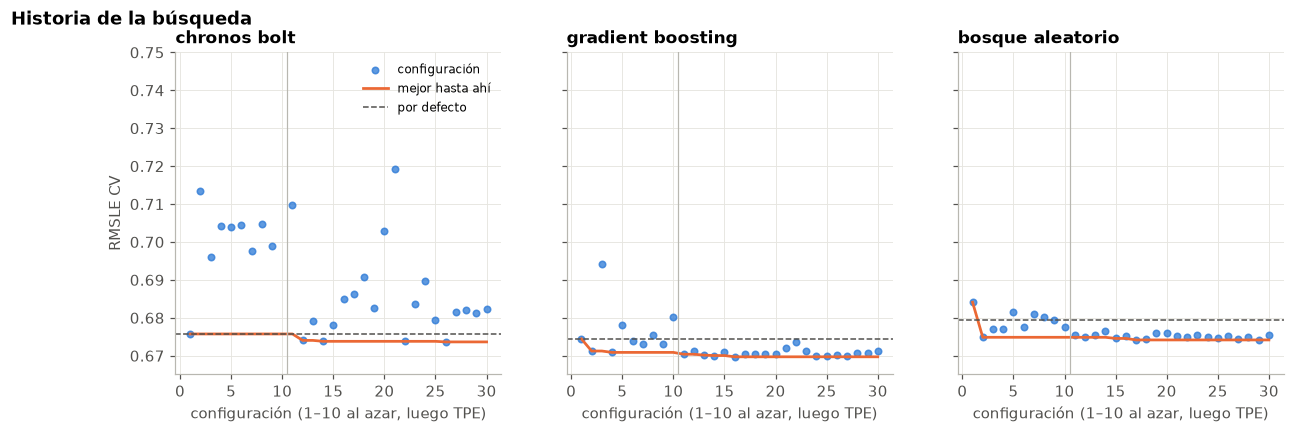

In [10]:
fig, ejes = plt.subplots(1, len(estudios), figsize=(13, 3.8), sharey=True)
for eje, (nombre, estudio) in zip(np.atleast_1d(ejes), estudios.items()):
    valores = np.array([t.value for t in estudio.trials])
    x = np.arange(1, len(valores) + 1)
    eje.scatter(x, valores, s=18, color=AZUL, alpha=0.75, label='configuración')
    eje.plot(x, np.minimum.accumulate(valores), color=NARANJA, linewidth=1.8, label='mejor hasta ahí')
    eje.axhline(resultados[nombre]['rmsle_cv_por_defecto'], color=TINTA_2, linestyle='--', linewidth=1,
                label='por defecto')
    eje.axvline(10.5, color=GRIS, linewidth=0.8)
    eje.set_title(nombre)
    eje.set_xlabel('configuración (1–10 al azar, luego TPE)')
eje0 = np.atleast_1d(ejes)[0]
eje0.set_ylabel('RMSLE CV')
eje0.set_ylim(top=min(0.75, eje0.get_ylim()[1]))
eje0.legend(frameon=False, fontsize=8)
fig.suptitle('Historia de la búsqueda', x=0.01, ha='left', fontweight='bold')
fig.savefig(f'{FIGURAS}/tuning_historia.png')
plt.show()

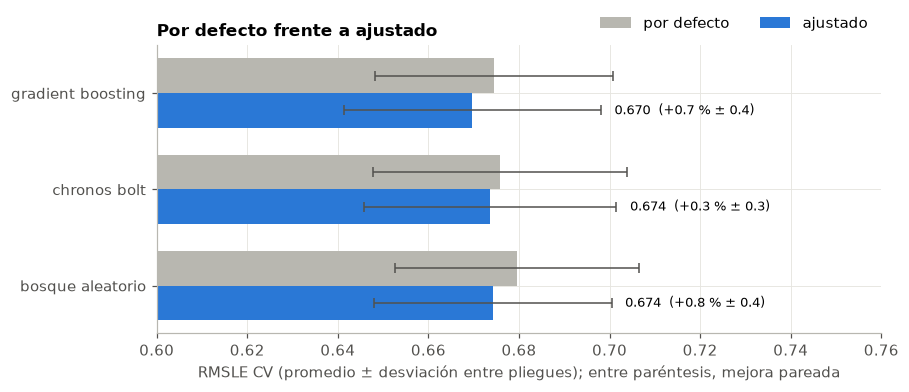

In [11]:
orden = tabla_tuning.sort_values('rmsle_cv', ascending=False)
y_pos = np.arange(len(orden))
alto = 0.36
fig, ax = plt.subplots(figsize=(8.5, 3.4))
ax.barh(y_pos + alto / 2, orden['rmsle_cv_por_defecto'], xerr=orden['rmsle_cv_std_por_defecto'], height=alto,
        color=GRIS, label='por defecto', error_kw={'ecolor': TINTA_2, 'capsize': 3, 'linewidth': 1})
ax.barh(y_pos - alto / 2, orden['rmsle_cv'], xerr=orden['rmsle_cv_std'], height=alto,
        color=AZUL, label='ajustado', error_kw={'ecolor': TINTA_2, 'capsize': 3, 'linewidth': 1})
for y, (_, f) in enumerate(orden.iterrows()):
    ax.text(f['rmsle_cv'] + f['rmsle_cv_std'] + 0.003, y - alto / 2,
            f"{f['rmsle_cv']:.3f}  ({f['mejora_pareada_pct']:+.1f} % ± {f['mejora_pareada_std_pct']:.1f})",
            va='center', fontsize=8.5)
ax.set_yticks(y_pos, orden.index)
ax.set_xlim(0.6, 0.76)
ax.set_xlabel('RMSLE CV (promedio ± desviación entre pliegues); entre paréntesis, mejora pareada')
ax.set_title('Por defecto frente a ajustado')
ax.legend(frameon=False, loc='lower right', bbox_to_anchor=(1.0, 1.0), ncol=2)  # fuera del área de datos
fig.savefig(f'{FIGURAS}/tuning_mejora.png')
plt.show()

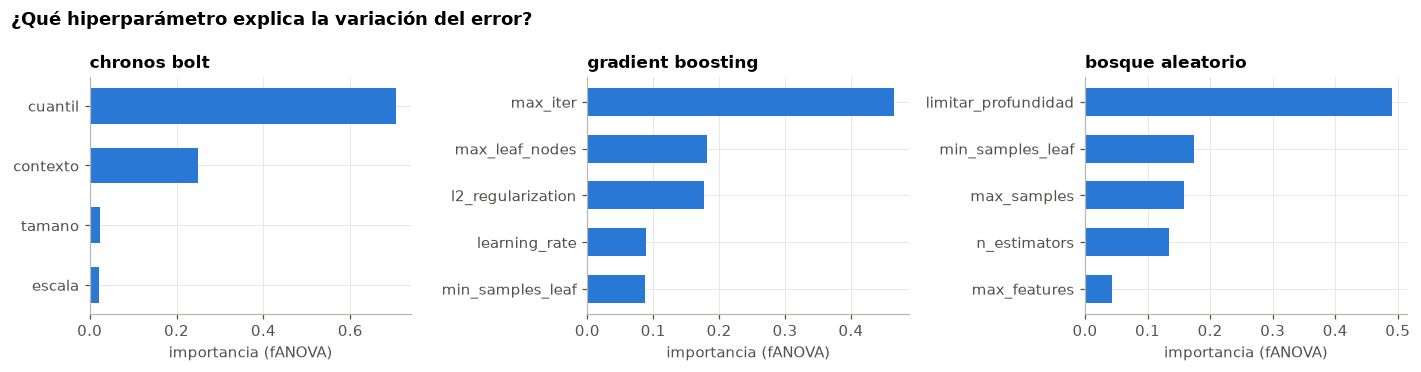

In [12]:
fig, ejes = plt.subplots(1, len(estudios), figsize=(13, 3.4))
for eje, (nombre, estudio) in zip(np.atleast_1d(ejes), estudios.items()):
    importancia = pd.Series(optuna.importance.get_param_importances(
        estudio, evaluator=optuna.importance.FanovaImportanceEvaluator(seed=SEMILLA))).sort_values()
    eje.barh(importancia.index, importancia.values, color=AZUL, height=0.6)
    eje.set_title(nombre)
    eje.set_xlabel('importancia (fANOVA)')
fig.suptitle('¿Qué hiperparámetro explica la variación del error?', x=0.01, ha='left', fontweight='bold')
fig.tight_layout()
fig.savefig(f'{FIGURAS}/tuning_importancia.png')
plt.show()

## 7. Interpretación

| Modelo | Por defecto | Ajustado ± desv. | Mejora pareada | Pliegues que mejora | ¿Supera la desviación? |
|---|---|---|---|---|---|
| Gradient boosting | 0,6744 | **0,6697 ± 0,028** | 0,71 % ± 0,40 | 4/5 | No |
| Chronos-Bolt | 0,6757 | 0,6737 ± 0,028 | 0,31 % ± 0,31 | 3/5 | No |
| Bosque aleatorio | 0,6795 | 0,6742 ± 0,026 | 0,78 % ± 0,40 | 5/5 | No |

**1. Según la regla del enunciado, ninguna mejora cuenta.** Las mejoras van de 0,002 a 0,005 de RMSLE, y la desviación
entre pliegues es de ~0,027. La conclusión honesta es que las configuraciones por defecto ya estaban cerca de su
óptimo para estas features.

**2. Las mejoras son pequeñas, pero no son ruido.** La desviación entre pliegues mide sobre todo cuánto cambia la
dificultad de una ventana de 16 días a otra: los pliegues van de ~0,64 a ~0,71 para *todos* los modelos. La
comparación pareada elimina esa variación común:

- gradient boosting mejora 0,71 % ± 0,40 y gana en 4 de 5 pliegues;
- el bosque mejora 0,78 % ± 0,40 y gana en los 5.

Son mejoras reales, pero pequeñas; Chronos (0,31 % ± 0,31, 3 de 5) queda en el límite.

**3. Cada modelo cambió como predecía el diagnóstico del notebook 03.**

- *Gradient boosting* no sobreajustaba (brecha ≈ 0), así que el tuning le dio **más capacidad**: 522 iteraciones con
  tasa 0,038, 181 hojas por árbol y mínimo 33 filas por hoja. La brecha subió a +0,049 y la CV bajó, que es el
  intercambio esperado. fANOVA confirma que `max_iter` explica casi la mitad de la variación del error.
- *El bosque* memorizaba (brecha +0,43). Con hojas de ≥ 10 filas, 33 % de las variables y 36 % de las filas por
  árbol, su brecha baja a **+0,053** y su CV mejora. La decisión más importante fue no limitar la profundidad: el
  control de las hojas regulariza mejor que un tope de profundidad.
- *Chronos* no se reentrena, así que solo se ajustó la inferencia. Lo que más pesa es el **cuantil**: el mejor es
  0,46, un poco por debajo de la mediana, porque en series intermitentes el RMSLE castiga más el sobrepronóstico
  de los días en cero. Ningún otro tamaño supera a *small* (mejor RMSLE: *base* 0,679, *mini* 0,682, *tiny*
  0,682 frente a 0,674): un modelo más grande no pronostica mejor estas series.

**4. El costo del tuning.** Las 90 configuraciones tomaron 8,2 h en total:

| Modelo | Tiempo de tuning |
|---|---|
| Gradient boosting | 4,8 h (hasta 800 iteraciones × 5 pliegues por configuración) |
| Bosque aleatorio | 2,9 h (gracias al espacio regularizado) |
| Chronos-Bolt | 0,5 h |

**Qué pasa a la selección (notebook 05).** Por RMSLE, los tres ajustados quedan prácticamente empatados: gradient
boosting 0,6697, Chronos 0,6737 y bosque 0,6742, con diferencias muy por debajo de la desviación entre pliegues. Por
eso el RMSLE **no decide** el ganador. El criterio de selección es la **métrica de negocio**: el costo de la regla de
reposición *newsvendor* en el escenario Co:Cu 1:3, medido solo en la validación. Los tres ajustados pasan al
notebook 05 con sus hiperparámetros, que también sirven de base para dos candidatos que pronostican directamente el
cuantil del pedido (GB-cuantil y Chronos-cuantil).

Resultado del notebook 05:

- **Champion: Chronos-Bolt cuantil 0,75.**
- **Challenger: GB-cuantil 0,75**, con la estructura de árboles ajustada aquí.
- El gradient boosting que gana por RMSLE queda como referencia: en costo apenas empata con la media de 28 días.
